# Sieci neuronowe – ćwiczenie 3
## Wielowarstwowa sieć neuronowa uczona propagacją wsteczną · zbiór Heart Disease (Cleveland)

**Dawid Pilarski** &nbsp;&nbsp; **Nr albumu:** 280468

> Kod przygotowany z pomocą narzędzia AI (Claude).

---

### Najważniejsze wyniki

| | |
|---|---|
| implementacja | moduły Linear, ReLU, sigmoida + entropia krzyżowa z `forward` i `backward`; gradient zgodny z numerycznym do ok. $10^{-10}$ |
| sieć 17-17-1 (α = 0,01, wagi N(0; 0,01)) | przez ok. **720 epok** stoi na koszcie 0,69, potem się uczy; najlepsza na walidacji w epoce **1783**: test **F1 = 0,764** |
| przeuczenie | po 30 000 epok koszt treningowy 0,031, walidacyjny rośnie z 0,393 do **0,909** |
| szerokość warstwy ukrytej | 2 → 256 neuronów: plateau krótsze (1055 → 428 epok), F1 przy early stopping ~0,76 dla każdej szerokości |
| normalizacja | dane surowe: regresja logistyczna się rozbiega, MLP utyka na koszcie 0,52 (F1 0,67); min-max i standaryzacja działają |
| liczba warstw | 0 / 1 / 2 / 3 warstwy: wyjście z plateau po ok. 22 / 765 / 7700 / 94 600 epokach; **4 warstwy nie ruszają** w 150 000 epok |
| przyczyna | gradient maleje kilka do kilkudziesięciu razy na każdą warstwę w stronę wejścia; inicjalizacja He usuwa plateau (24–55 epok) |

**Spis treści:** 1. Cel · 2. Model i implementacja · 3. Model bazowy · 4. Szerokość warstwy ukrytej · 5. Dane znormalizowane i nieznormalizowane · 6. Liczba warstw · 7. Dodatkowo: inicjalizacja He · 8. Podsumowanie · 9. Wnioski

## 1. Cel ćwiczenia

Implementacja wielowarstwowej sieci neuronowej (MLP) z funkcją aktywacji **ReLU** i funkcją kosztu jak w regresji logistycznej (sigmoida + entropia krzyżowa), uczonej **algorytmem propagacji wstecznej**. Każda operacja jest osobnym modułem z `forward` i `backward`, a gradienty wag liczone są regułą łańcuchową od kosztu w stronę wejścia.

Badam, jak sieć zachowuje się na zbinaryzowanym zbiorze Heart Disease dla:

- różnej **wymiarowości warstwy ukrytej**: znacznie mniejszej od liczby cech, równej jej i znacznie większej,
- danych **znormalizowanych i nieznormalizowanych**,
- różnej **liczby warstw**.

Zgodnie z treścią wagi inicjalizuję z rozkładu Gaussa N(0; 0,01), a współczynnik uczenia to α = 0,01 (pełny batch).

## 2. Model i implementacja

### 2.1. Propagacja wsteczna jako sekwencja modułów

Sieć to złożenie operacji $L(f_K(\dots f_2(f_1(x))))$. Reguła łańcuchowa daje $\dfrac{\partial L}{\partial x_{k-1}} = \dfrac{\partial L}{\partial x_k}\,\dfrac{\partial x_k}{\partial x_{k-1}}$, więc każdy moduł potrzebuje tylko dwóch funkcji:

- `forward(x)`: liczy wyjście i **zapamiętuje wejście** (będzie potrzebne przy przejściu wstecz),
- `backward(dL/dy)`: liczy gradient po swoich wagach (jeśli je ma) i **zwraca $\partial L/\partial x$** dla modułu poprzedniego.

Przejście w przód idzie w kolejności operacji, przejście wstecz w kolejności odwrotnej.

| moduł | forward | backward (dla jednego przykładu, $\partial L/\partial y$ – wektor wierszowy) |
|---|---|---|
| Linear | $y = Wx + b$ | $\dfrac{\partial L}{\partial W} = \left(\dfrac{\partial L}{\partial y}\right)^{T} x^{T}$, $\;\dfrac{\partial L}{\partial b} = \dfrac{\partial L}{\partial y}$, $\;\dfrac{\partial L}{\partial x} = \dfrac{\partial L}{\partial y}\,W$ |
| ReLU | $y = \max(0, x)$ | $\dfrac{\partial L}{\partial x} = \dfrac{\partial L}{\partial y} \odot [x > 0]$ (macierz diagonalna → mnożenie element-wise) |
| sigmoida + BCE | $p = \sigma(z)$, $L = -\frac{1}{N}\sum[y\ln p + (1-y)\ln(1-p)]$ | $\dfrac{\partial L}{\partial z} = \dfrac{p - y}{N}$ (jak w ćw. 2) |

W kodzie wiersz macierzy $X$ to jeden przykład, więc paczka $N$ przykładów ma kształt $(N, d)$, a $\partial L/\partial y$ kształt $(N, d_y)$: to ta sama konwencja co w treści, tylko dla wielu przykładów naraz. Gradient wag to suma po przykładach: `dW = dY.T @ X`.

Sieć ma postać: Linear → ReLU → … → Linear → sigmoida + BCE. Bez warstw ukrytych to dokładnie regresja logistyczna z ćw. 2.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())
from data import load_splits          # przygotowanie danych z ćw. 1

SEED = 42
LR = 0.01            # współczynnik uczenia z treści
INIT_SCALE = 0.01    # odchylenie wag początkowych z treści
pd.set_option("display.precision", 4)

# wspólny styl wykresów
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (12, 4), "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
    "legend.frameon": False,
})
C = {"train": "#1f5f8b", "val": "#e07b39", "ref": "#808080",
     "f1": "#1f5f8b", "precision": "#3a9d5d", "recall": "#b0478a"}

def rys(fig, nr, tytul):
    fig.suptitle(f"Rys. {nr}. {tytul}", fontsize=12, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

Pierwsza komórka: importy, stałe z treści listy (`LR = 0.01`, `INIT_SCALE = 0.01`), styl wykresów i funkcja `rys`, która podpisuje rysunki.

### 2.2. Implementacja (NumPy, bez gotowych metod uczenia)

In [2]:
def sigmoid(z):
    # wersja stabilna numerycznie: brak przepełnienia exp dla dużych |z|
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(float)
    tp = np.sum((yhat == 1) & (y == 1)); fp = np.sum((yhat == 1) & (y == 0))
    fn = np.sum((yhat == 0) & (y == 1)); tn = np.sum((yhat == 0) & (y == 0))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(precision=prec, recall=rec, f1=f1, accuracy=(tp + tn) / len(y))

- `sigmoid` jest napisana w wersji stabilnej numerycznie: dla dużych ujemnych $z$ liczy $\frac{e^z}{1+e^z}$, żeby `exp` się nie przepełnił,
- `bce` to entropia krzyżowa; przycina $p$ do $[10^{-12}, 1-10^{-12}]$, żeby nie liczyć $\ln 0$,
- `metrics` liczy TP, FP, FN, TN przy progu 0,5, a z nich precision, recall, F1 i accuracy.

In [3]:
class Linear:
    # y = W x + b, W: (n_out, n_in); wagi z N(0; scale) albo He: N(0; sqrt(2 / n_in))
    def __init__(self, n_in, n_out, rng, scale=INIT_SCALE, init="normal"):
        std = np.sqrt(2.0 / n_in) if init == "he" else scale
        self.W = rng.normal(0.0, std, (n_out, n_in))
        self.b = np.zeros(n_out)

    def forward(self, X):
        self.X = X                         # zapamiętane na potrzeby backward
        return X @ self.W.T + self.b

    def backward(self, dY):                # dY = dL/dy, (N, n_out)
        self.dW = dY.T @ self.X            # dL/dW, (n_out, n_in)
        self.db = dY.sum(0)                # dL/db
        return dY @ self.W                 # dL/dx, (N, n_in)

class ReLU:
    def forward(self, X):
        self.mask = X > 0
        return X * self.mask

    def backward(self, dY):
        return dY * self.mask              # macierz diagonalna -> mnożenie element-wise

class SigmoidBCE:
    # sigmoida na wyjściu + entropia krzyżowa: pochodna upraszcza się do (p - y) / N
    def forward(self, z, y):
        self.p, self.y = sigmoid(z), y
        return bce(y, self.p)

    def backward(self):
        return ((self.p - self.y) / len(self.y))[:, None]

Trzy moduły, każdy z `forward` i `backward`:
- `Linear`: forward zapamiętuje wejście `X` i liczy $Wx + b$; backward dostaje $\partial L/\partial y$, zapisuje gradienty wag `dW`, `db` i oddaje $\partial L/\partial x$ w dół,
- `ReLU`: forward zapamiętuje maskę $[x > 0]$; backward mnoży gradient element po elemencie przez tę maskę,
- `SigmoidBCE`: sigmoida razy koszt w jednym module, backward od razu zwraca $(p - y)/N$.

In [4]:
class MLP:
    # hidden: liczby neuronów kolejnych warstw ukrytych; () = regresja logistyczna z ćw. 2
    def __init__(self, n_in, hidden=(17,), init="normal", init_scale=INIT_SCALE, seed=SEED):
        rng = np.random.default_rng(seed)
        self.layers, prev = [], n_in
        for h in hidden:
            self.layers += [Linear(prev, h, rng, init_scale, init), ReLU()]
            prev = h
        self.layers.append(Linear(prev, 1, rng, init_scale, init))
        self.linears = [l for l in self.layers if isinstance(l, Linear)]
        self.loss_fn = SigmoidBCE()

    def forward(self, X):
        for layer in self.layers:                  # w przód: w kolejności operacji
            X = layer.forward(X)
        return X[:, 0]

    def predict_proba(self, X):
        return sigmoid(self.forward(X))

    def loss_and_grad(self, X, y):
        loss = self.loss_fn.forward(self.forward(X), y)
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):        # wstecz: w odwrotnej kolejności
            d = layer.backward(d)
        return loss

    def step(self, lr):
        for l in self.linears:
            l.W -= lr * l.dW
            l.b -= lr * l.db

    def get_params(self):
        return [(l.W.copy(), l.b.copy()) for l in self.linears]

    def set_params(self, params):
        for l, (W, b) in zip(self.linears, params):
            l.W, l.b = W.copy(), b.copy()

    def fit(self, X, y, Xv, yv, lr=LR, epochs=1000, log_every=10):
        # koszt co epokę, metryki i normy gradientu co log_every epok; pamięta wagi z najniższym kosztem walidacyjnym
        h = {k: [] for k in ["loss", "val_loss", "log_epoch", "val_f1", "val_precision", "val_recall", "grad_norms"]}
        best = (np.inf, None, 0)
        for ep in range(epochs):
            loss = self.loss_and_grad(X, y)
            pv = self.predict_proba(Xv)
            h["loss"].append(loss); h["val_loss"].append(bce(yv, pv))
            if h["val_loss"][-1] < best[0] - 1e-9:
                best = (h["val_loss"][-1], self.get_params(), ep)
            if ep % log_every == 0 or ep == epochs - 1:
                mv = metrics(yv, pv)
                h["log_epoch"].append(ep); h["val_f1"].append(mv["f1"])
                h["val_precision"].append(mv["precision"]); h["val_recall"].append(mv["recall"])
                h["grad_norms"].append([float(np.sqrt(np.sum(l.dW ** 2) + np.sum(l.db ** 2))) for l in self.linears])
            if not np.isfinite(loss):
                break
            self.step(lr)
        self.history = h
        self.best_val_loss, self.best_params, self.best_epoch = best
        return self

    def early_stopping_proba(self, X):
        # predykcje dla wag z najniższym kosztem walidacyjnym (early stopping)
        last = self.get_params(); self.set_params(self.best_params)
        p = self.predict_proba(X); self.set_params(last)
        return p

def epochs_to(loss_hist, target):
    idx = np.where(np.asarray(loss_hist) <= target)[0]
    return int(idx[0]) if len(idx) else None

PLATEAU = 0.6        # koszt stałej odpowiedzi to ok. 0,69; "wyjście z plateau" = koszt < 0,6

Klasa `MLP` układa moduły w listę: (Linear → ReLU) dla każdej warstwy ukrytej i Linear z 1 neuronem na końcu.
- `forward` przechodzi listę w kolejności, `loss_and_grad` liczy koszt i przechodzi listę **od końca** (`reversed`), wywołując `backward`,
- `step` robi krok $W \leftarrow W - \alpha\, \partial L/\partial W$ dla każdej warstwy liniowej,
- `fit` w każdej epoce: koszt i gradient na całym zbiorze treningowym, koszt walidacyjny, zapamiętanie wag z najniższym kosztem walidacyjnym (early stopping), krok,
- `epochs_to` zwraca pierwszą epokę, w której koszt spadł poniżej progu; `PLATEAU = 0.6` to próg „wyjścia z plateau”.

### 2.3. Dane

Przygotowanie z ćw. 1 (`data.py`): braki uzupełnione dominantą, cechy kategoryczne zakodowane one-hot, standaryzacja parametrami ze zbioru treningowego, podział warstwowy 60/20/20. Wariant **min-max** (zakres [0, 1]) i dane **surowe** liczę z tych samych kolumn przed standaryzacją.

In [5]:
def load_data(scaling="standard", seed=SEED):
    # 'standard' (średnia 0, odchylenie 1), 'minmax' ([0, 1]), 'none' (surowe); statystyki z treningu
    if scaling == "standard":
        return load_splits(seed=seed, standardize=True)
    (Xtr, ytr), (Xva, yva), (Xte, yte), names = load_splits(seed=seed, standardize=False)
    if scaling == "minmax":
        lo, hi = Xtr.min(0), Xtr.max(0)
        span = np.where(hi > lo, hi - lo, 1.0)
        Xtr, Xva, Xte = [(X - lo) / span for X in (Xtr, Xva, Xte)]
    return (Xtr, ytr), (Xva, yva), (Xte, yte), names

(Xtr, ytr), (Xva, yva), (Xte, yte), names = load_data()
d = Xtr.shape[1]
pd.DataFrame({"liczba pacjentów": [len(ytr), len(yva), len(yte)],
              "odsetek chorych": [ytr.mean(), yva.mean(), yte.mean()]},
             index=["treningowy", "walidacyjny", "testowy"]).round(3).assign(**{"liczba cech": d})

,liczba pacjentów,odsetek chorych,liczba cech
treningowy,181,0.459,17
walidacyjny,61,0.459,17
testowy,61,0.459,17


Zbiór treningowy (181 pacjentów) służy do uczenia, walidacyjny (61) do wyboru najlepszej epoki, a testowy (61) tylko do końcowej oceny. `load_data("minmax")` i `load_data("none")` dają te same kolumny przeskalowane do [0, 1] albo surowe.

### 2.4. Testy poprawności propagacji wstecznej

Gradient z `backward` porównuję z gradientem numerycznym $\dfrac{L(w+h) - L(w-h)}{2h}$ dla **każdej wagi** sieci z dwiema warstwami ukrytymi. Dodatkowo sieć bez warstw ukrytych musi dawać ten sam gradient co wzór z ćw. 2: $-\frac{1}{N}X^T(y - p)$.

In [6]:
def numeric_grad(f, A, h=1e-6):
    # różnice centralne po każdym elemencie A
    g = np.zeros_like(A)
    for i in np.ndindex(A.shape):
        old = A[i]
        A[i] = old + h; fp = f()
        A[i] = old - h; fm = f()
        A[i] = old; g[i] = (fp - fm) / (2 * h)
    return g

rng = np.random.default_rng(3)
X = rng.normal(size=(20, 5)); y = (rng.random(20) > 0.5).astype(float)
net = MLP(5, (6, 4), init_scale=0.5, seed=3)       # 2 warstwy ukryte, większe wagi, żeby gradienty były wyraźne
net.loss_and_grad(X, y)
rows = {}
for i, l in enumerate(net.linears, 1):
    f = lambda: bce(y, net.predict_proba(X))
    rows[f"warstwa liniowa {i}  {l.W.shape[1]}→{l.W.shape[0]}"] = {
        "max |dW − dW_num|": f"{np.max(np.abs(l.dW - numeric_grad(f, l.W))):.1e}",
        "max |db − db_num|": f"{np.max(np.abs(l.db - numeric_grad(f, l.b))):.1e}"}

# 0 warstw ukrytych = regresja logistyczna z ćw. 2
lr0 = MLP(d, (), seed=0); lr0.loss_and_grad(Xtr, ytr)
diff = np.max(np.abs(lr0.linears[0].dW[0] + Xtr.T @ (ytr - lr0.predict_proba(Xtr)) / len(ytr)))
rows["0 warstw ukrytych vs wzór z ćw. 2"] = {"max |dW − dW_num|": f"{diff:.1e}", "max |db − db_num|": "—"}
pd.DataFrame(rows).T

,max |dW − dW_num|,max |db − db_num|
warstwa liniowa 1 5→6,1.0e-10,9.4e-11
warstwa liniowa 2 6→4,1.1e-10,2.9e-11
warstwa liniowa 3 4→1,9.8e-11,4.7e-11
0 warstw ukrytych vs wzór z ćw. 2,2.2e-16,—


`numeric_grad` zmienia każdą wagę o $\pm 10^{-6}$ i liczy różnicę kosztu, czyli gradient numeryczny. Porównuję go z `dW` i `db` z propagacji wstecznej dla każdej warstwy sieci 5 → 6 → 4 → 1.

> **Wniosek:** gradienty z propagacji wstecznej zgadzają się z numerycznymi do ok. $10^{-10}$ w każdej warstwie, a sieć bez warstw ukrytych liczy dokładnie gradient regresji logistycznej. Implementacja jest poprawna.

## 3. Model bazowy

Sieć **17-17-1**: jedna warstwa ukryta o szerokości równej liczbie cech, ReLU, α = 0,01, wagi N(0; 0,01), 30 000 epok. Oprócz wag końcowych zapamiętuję wagi z najniższym kosztem walidacyjnym (**early stopping**). Za „wyjście z plateau” przyjmuję pierwszą epokę, w której koszt treningowy spadł poniżej 0,6. Koszt stałej odpowiedzi (p = odsetek chorych dla każdego pacjenta) to 0,690.

In [7]:
E = 30_000
base = MLP(d, (d,), seed=0).fit(Xtr, ytr, Xva, yva, epochs=E)
h = base.history
print(f"wyjście z plateau (koszt < {PLATEAU}): epoka {epochs_to(h['loss'], PLATEAU)}; "
      f"najniższy koszt walidacyjny {base.best_val_loss:.3f} w epoce {base.best_epoch}")
pd.DataFrame({
    "wagi końcowe (30 000 epok)": {"koszt train": h["loss"][-1], "koszt val": h["val_loss"][-1],
                                   **{f"{k} test": v for k, v in metrics(yte, base.predict_proba(Xte)).items()}},
    f"early stopping (epoka {base.best_epoch})": {"koszt train": h["loss"][base.best_epoch], "koszt val": base.best_val_loss,
                                   **{f"{k} test": v for k, v in metrics(yte, base.early_stopping_proba(Xte)).items()}},
}).T.round(3)

wyjście z plateau (koszt < 0.6): epoka 724; najniższy koszt walidacyjny 0.393 w epoce 1783


,koszt train,koszt val,precision test,recall test,f1 test,accuracy test
wagi końcowe (30 000 epok),0.031,0.909,0.786,0.786,0.786,0.803
early stopping (epoka 1783),0.291,0.393,0.778,0.750,0.764,0.787


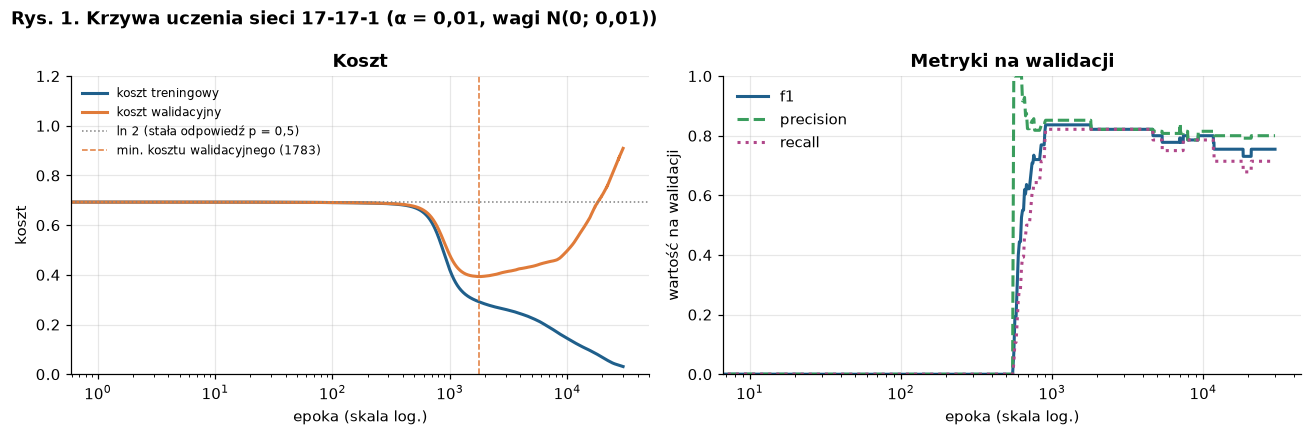

In [8]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(h["loss"], c=C["train"], lw=2, label="koszt treningowy")
ax[0].plot(h["val_loss"], c=C["val"], lw=2, label="koszt walidacyjny")
ax[0].axhline(np.log(2), ls=":", c=C["ref"], lw=1, label="ln 2 (stała odpowiedź p = 0,5)")
ax[0].axvline(base.best_epoch, ls="--", c=C["val"], lw=1, label=f"min. kosztu walidacyjnego ({base.best_epoch})")
ax[0].set(xscale="log", ylim=(0, 1.2), xlabel="epoka (skala log.)", ylabel="koszt", title="Koszt")
ax[0].legend(fontsize=8)
for k, ls in [("f1", "-"), ("precision", "--"), ("recall", ":")]:
    ax[1].plot(h["log_epoch"], h["val_" + k], ls, c=C[k], lw=2, label=k)
ax[1].set(xscale="log", ylim=(0, 1), xlabel="epoka (skala log.)", ylabel="wartość na walidacji", title="Metryki na walidacji")
ax[1].legend()
rys(fig, 1, "Krzywa uczenia sieci 17-17-1 (α = 0,01, wagi N(0; 0,01))")

**Jak czytać Rys. 1:** po lewej koszt w kolejnych epokach (oś x logarytmiczna: 10² = 100, 10³ = 1000, 10⁴ = 10 000). Niebieska linia to koszt treningowy, pomarańczowa walidacyjny, szara kropkowana to ln 2 = 0,693, czyli koszt sieci, która każdemu daje 50%. Pionowa przerywana linia to epoka z najniższym kosztem walidacyjnym. Po prawej F1, precision i recall na walidacji.

**Obserwacje:**
- przez pierwsze ok. **720 epok** koszt stoi na 0,69, a F1 = 0: wagi są tak małe, że sieć zwraca p ≈ 0,5 dla każdego pacjenta, a gradient jest bliski zera. To **plateau**, a nie minimum,
- potem koszt szybko spada, a najniższy koszt walidacyjny (0,393) jest w epoce **1783**. Na walidacji F1 = 0,84, na teście F1 = 0,764 (21 chorych wykrytych, 6 fałszywych alarmów, 7 pominiętych),
- dalej sieć **zapamiętuje** zbiór treningowy: po 30 000 epok koszt treningowy to 0,031 (accuracy 98%), a walidacyjny rośnie do 0,909, czyli ponad dwa razy więcej niż w minimum,
- F1 testowe po 30 000 epok (0,786) prawie się nie zmienia, bo F1 zależy tylko od strony progu 0,5. Koszt walidacyjny pokazuje jednak, że model jest coraz pewniejszy swoich błędów.

> **Wniosek:** w przeciwieństwie do regresji logistycznej sieć z warstwą ukrytą może dopasować się do danych treningowych prawie idealnie, więc warunek stopu (early stopping) jest konieczny. Przy tak małych wagach początkowych uczenie zaczyna się od długiego plateau.

## 4. Wymiarowość warstwy ukrytej

Jedna warstwa ukryta o szerokości **2 i 4** (znacznie mniej niż 17 cech), **17** (równo), **68 i 256** (znacznie więcej). Dla każdej szerokości 3 losowania wag i średnia.

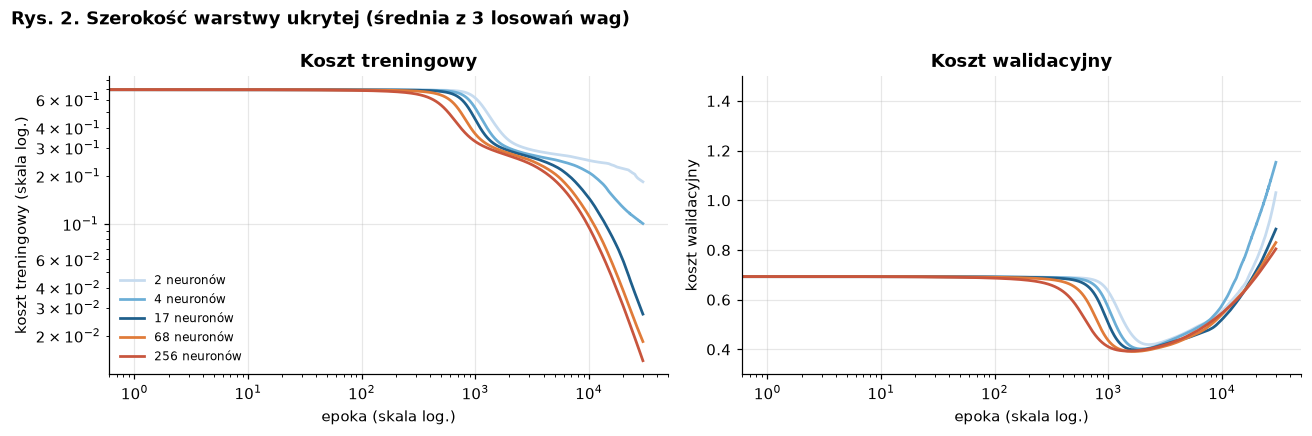

,parametry,wyjście z plateau,koszt train po 30 000,min. koszt val,epoka min. val,koszt val po 30 000,F1 test (early stopping),F1 test (po 30 000)
neuronów,,,,,,,,
2,39.0,1055.0,0.1838,0.419,2274.0,1.031,0.756,0.702
4,77.0,880.0,0.1006,0.402,1973.0,1.153,0.764,0.773
17,324.0,766.0,0.0273,0.397,1811.0,0.884,0.764,0.771
68,1293.0,597.0,0.0184,0.392,1677.0,0.830,0.764,0.786
256,4865.0,428.0,0.0140,0.393,1518.0,0.804,0.764,0.793


In [9]:
SEEDS = (0, 1, 2)
widths = [2, 4, d, 4 * d, 256]
cols = ["#c6dbef", "#6baed6", "#1f5f8b", "#e07b39", "#c8553d"]
rows, curves = {}, {}
for w in widths:
    runs = [MLP(d, (w,), seed=s).fit(Xtr, ytr, Xva, yva, epochs=E, log_every=100) for s in SEEDS]
    exits = [epochs_to(r.history["loss"], PLATEAU) for r in runs]
    rows[w] = {"parametry": (d + 1) * w + w + 1,
               "wyjście z plateau": round(np.mean([e for e in exits if e is not None])),
               "koszt train po 30 000": round(np.mean([r.history["loss"][-1] for r in runs]), 4),
               "min. koszt val": round(np.mean([r.best_val_loss for r in runs]), 3),
               "epoka min. val": round(np.mean([r.best_epoch for r in runs])),
               "koszt val po 30 000": round(np.mean([r.history["val_loss"][-1] for r in runs]), 3),
               "F1 test (early stopping)": round(np.mean([metrics(yte, r.early_stopping_proba(Xte))["f1"] for r in runs]), 3),
               "F1 test (po 30 000)": round(np.mean([metrics(yte, r.predict_proba(Xte))["f1"] for r in runs]), 3)}
    curves[w] = (np.mean([r.history["loss"] for r in runs], 0), np.mean([r.history["val_loss"] for r in runs], 0))
fig, ax = plt.subplots(1, 2)
for col, w in zip(cols, widths):
    ax[0].plot(curves[w][0], c=col, lw=1.8, label=f"{w} neuronów")
    ax[1].plot(curves[w][1], c=col, lw=1.8, label=f"{w} neuronów")
ax[0].set(xscale="log", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title="Koszt treningowy")
ax[1].set(xscale="log", ylim=(0.3, 1.5), xlabel="epoka (skala log.)", ylabel="koszt walidacyjny", title="Koszt walidacyjny")
ax[0].legend(fontsize=8)
rys(fig, 2, "Szerokość warstwy ukrytej (średnia z 3 losowań wag)")
pd.DataFrame(rows).T.rename_axis("neuronów")

**Jak czytać Rys. 2:** każda linia to średnia z 3 losowań wag dla jednej szerokości warstwy ukrytej. Jasnoniebieskie to wąskie warstwy (2 i 4 neurony), ciemnoniebieska 17 (tyle co cech), pomarańczowa i czerwona szerokie (68 i 256). Po lewej koszt treningowy (obie osie logarytmiczne), po prawej walidacyjny.

**Obserwacje:**
- im szersza warstwa, tym **krótsze plateau**: 1055 epok dla 2 neuronów, 766 dla 17, 428 dla 256. Gradient wag wyjściowych to suma po wszystkich neuronach ukrytych, więc przy większej liczbie neuronów sygnał jest silniejszy,
- wąska sieć (2 neurony) ma za małą pojemność, żeby zapamiętać trening: koszt końcowy 0,18. Szerokie sieci schodzą do 0,014–0,018,
- **najniższy koszt walidacyjny** jest prawie taki sam dla każdej szerokości (0,39–0,42), a F1 testowe przy early stopping wynosi ok. 0,76 dla każdej szerokości. Na 61 pacjentach jedna osoba zmienia F1 o ok. 0,02,
- po 30 000 epok wszystkie sieci są przeuczone (koszt walidacyjny 0,80–1,15).

> **Wniosek:** szerokość warstwy ukrytej wpływa na szybkość uczenia i na to, jak bardzo sieć może się przeuczyć, ale nie na jakość przy dobrym warunku stopu. Na tym małym zbiorze (181 pacjentów) najlepsza sieć nie jest lepsza od regresji logistycznej.

## 5. Dane znormalizowane i nieznormalizowane

Ta sama sieć 17-17-1 i, dla porównania, sieć bez warstwy ukrytej (regresja logistyczna) na danych surowych (cholesterol ok. 250, oldpeak ok. 1, cechy 0/1), przeskalowanych min-max do [0, 1] i standaryzowanych. α = 0,01 w każdym przypadku.

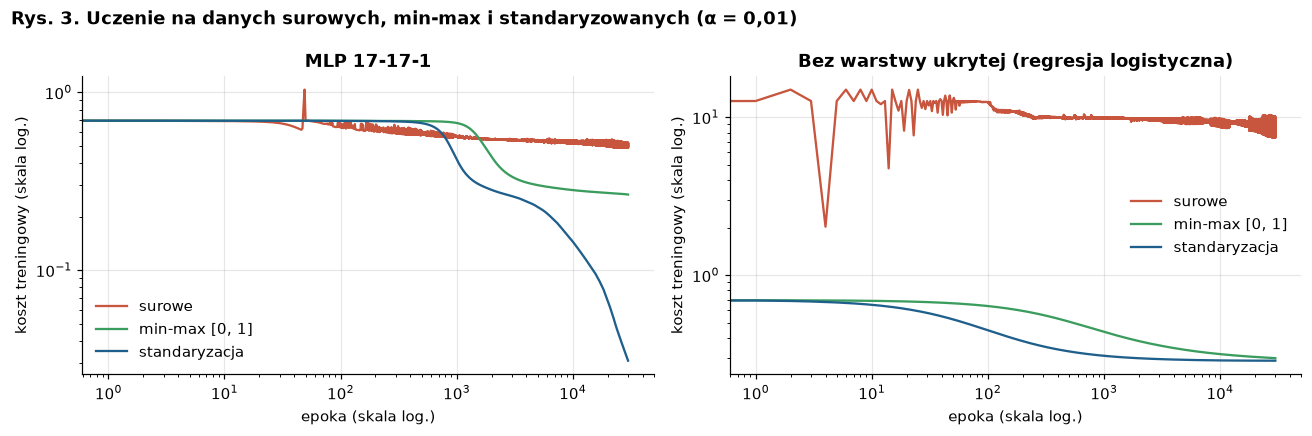

wskaźnik uwarunkowania XᵀX: surowe 5.52e+06, min-max [0, 1] 2.50e+02, standaryzacja 4.58e+01


koszt start  koszt po 30 000  \
surowe         MLP 17-17-1                0.693            0.519   
               bez warstwy ukrytej        1.061            7.969   
min-max [0, 1] MLP 17-17-1                0.693            0.266   
               bez warstwy ukrytej        0.694            0.298   
standaryzacja  MLP 17-17-1                0.693            0.031   
               bez warstwy ukrytej        0.696            0.287   

                                    min. koszt train  \
surowe         MLP 17-17-1                     0.488   
               bez warstwy ukrytej             1.061   
min-max [0, 1] MLP 17-17-1                     0.266   
               bez warstwy ukrytej             0.298   
standaryzacja  MLP 17-17-1                     0.031   
               bez warstwy ukrytej             0.287   

                                    oscylacje (wzrosty w ost. 500 ep.)  \
surowe         MLP 17-17-1                                       250.0   
               bez warstwy ukrytej                               247.0   
min-max [0, 1] MLP 17-17-1                                         0.0   
               bez warstwy ukrytej                                 0.0   
standaryzacja  MLP 17-17-1                                        35.0   
               bez warstwy ukrytej                                 0.0   

                                    min. koszt val  F1 test (early stopping)  
surowe         MLP 17-17-1                   0.646                     0.667  
               bez warstwy ukrytej           1.040                     0.629  
min-max [0, 1] MLP 17-17-1                   0.408                     0.750  
               bez warstwy ukrytej           0.390                     0.772  
standaryzacja  MLP 17-17-1                   0.393                     0.764  
               bez warstwy ukrytej           0.387                     0.764

In [10]:
rows, cond = {}, {}
fig, ax = plt.subplots(1, 2)
for col, (sc, label) in zip(["#c8553d", "#3a9d5d", "#1f5f8b"],
                             [("none", "surowe"), ("minmax", "min-max [0, 1]"), ("standard", "standaryzacja")]):
    (Xa, ya), (Xb, yb), (Xc, yc), _ = load_data(sc)
    cond[label] = np.linalg.cond(Xa.T @ Xa)
    for i, (arch, hidden) in enumerate([("MLP 17-17-1", (d,)), ("bez warstwy ukrytej", ())]):
        m = MLP(d, hidden, seed=0).fit(Xa, ya, Xb, yb, epochs=E, log_every=100)
        L = np.array(m.history["loss"])
        rows[(label, arch)] = {"koszt start": round(L[0], 3), "koszt po 30 000": round(L[-1], 3),
                               "min. koszt train": round(L.min(), 3),
                               "oscylacje (wzrosty w ost. 500 ep.)": int(np.sum(np.diff(L[-500:]) > 0)),
                               "min. koszt val": round(m.best_val_loss, 3),
                               "F1 test (early stopping)": round(metrics(yc, m.early_stopping_proba(Xc))["f1"], 3)}
        ax[i].plot(L, c=col, lw=1.5, label=label)
ax[0].set(xscale="log", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title="MLP 17-17-1")
ax[1].set(xscale="log", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title="Bez warstwy ukrytej (regresja logistyczna)")
ax[0].legend(); ax[1].legend()
rys(fig, 3, "Uczenie na danych surowych, min-max i standaryzowanych (α = 0,01)")
print("wskaźnik uwarunkowania XᵀX:", ", ".join(f"{k} {v:.2e}" for k, v in cond.items()))
pd.DataFrame(rows).T

**Jak czytać Rys. 3:** po lewej sieć 17-17-1, po prawej dla porównania sieć bez warstwy ukrytej (regresja logistyczna). Czerwona linia to dane surowe, zielona min-max, niebieska standaryzowane. Obie osie logarytmiczne.

**Obserwacje:**
- wskaźnik uwarunkowania $X^TX$: surowe **5,5 mln**, min-max 250, standaryzacja 46,
- **surowe dane, regresja logistyczna:** α = 0,01 jest za duże dla kierunku cholesterolu (w ćw. 2 próg stabilności wynosił ok. $7\cdot10^{-5}$), więc koszt skacze i po 30 000 epok wynosi ok. 8, a F1 testowe 0,63,
- **surowe dane, MLP:** sieć nie rozbiega się (wagi N(0; 0,01) są małe, a ReLU obcina część sygnału), ale utyka na koszcie ok. 0,52 z oscylacjami, a F1 testowe to tylko 0,67,
- **min-max:** obie sieci się uczą, ale wolniej niż na standaryzowanych: MLP wychodzi z plateau dopiero po ok. 1400 epokach (standaryzacja: 724), a po 30 000 epok koszt to 0,27 zamiast 0,03,
- **standaryzacja:** najszybsze uczenie i najmniejszy koszt; F1 przy early stopping 0,75–0,77 dla min-max i standaryzacji.

> **Wniosek:** bez normalizacji przy α = 0,01 sieć się nie uczy, bo cechy o dużych wartościach dominują gradient i krok jest dla nich za długi, a dla cech 0/1 za krótki. Normalizacja (min-max albo standaryzacja) jest konieczna. Standaryzacja działa lepiej, bo daje cechom średnią 0 i podobną skalę.

## 6. Liczba warstw

Od 0 do 4 warstw ukrytych po 17 neuronów, α = 0,01, wagi N(0; 0,01), **150 000 epok**, 3 losowania. Po prawej norma gradientu każdej warstwy liniowej w pierwszej epoce.

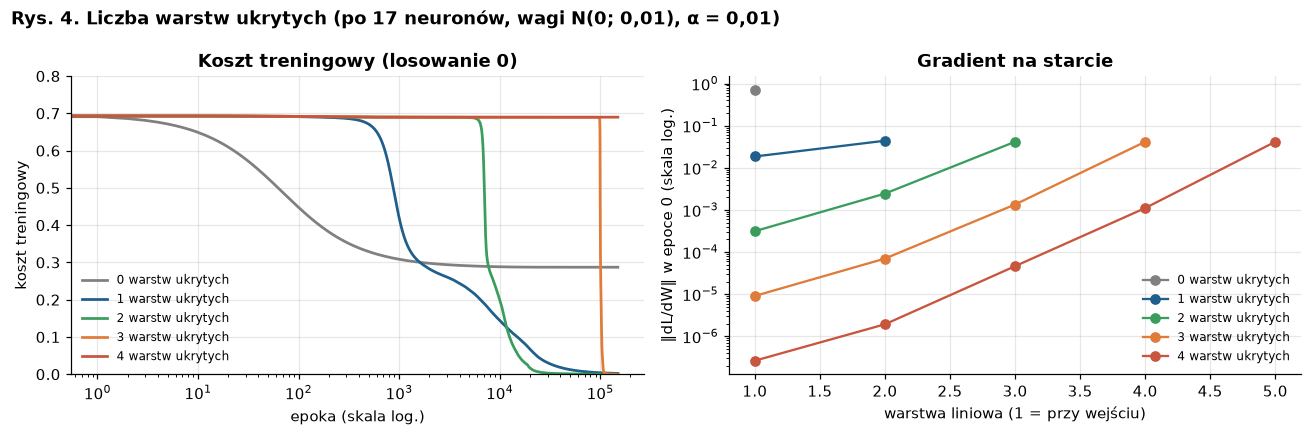

,wyjście z plateau (3 losowania),koszt train po 150 000,min. koszt val,F1 test (early stopping)
warstw ukrytych,,,,
0,23 / 21 / 21,0.2872,0.387,0.764
1,724 / 814 / 759,0.0018,0.397,0.764
2,6862 / 7368 / 8835,0.0002,0.399,0.764
3,99838 / 90854 / 93052,0.0002,0.418,0.75
4,— / — / —,0.6897,0.69,0.0


In [11]:
E_DEPTH = 150_000
depths = [0, 1, 2, 3, 4]
cols = ["#808080", "#1f5f8b", "#3a9d5d", "#e07b39", "#c8553d"]
rows, dcurves, grad0 = {}, {}, {}
for n in depths:
    runs = [MLP(d, (d,) * n, seed=s).fit(Xtr, ytr, Xva, yva, epochs=E_DEPTH, log_every=1000) for s in SEEDS]
    exits = [epochs_to(r.history["loss"], PLATEAU) for r in runs]
    rows[n] = {"wyjście z plateau (3 losowania)": " / ".join("—" if e is None else str(e) for e in exits),
               "koszt train po 150 000": round(np.mean([r.history["loss"][-1] for r in runs]), 4),
               "min. koszt val": round(np.mean([r.best_val_loss for r in runs]), 3),
               "F1 test (early stopping)": round(np.mean([metrics(yte, r.early_stopping_proba(Xte))["f1"] for r in runs]), 3)}
    dcurves[n] = runs[0].history["loss"]; grad0[n] = runs[0].history["grad_norms"][0]
fig, ax = plt.subplots(1, 2)
for col, n in zip(cols, depths):
    ax[0].plot(dcurves[n], c=col, lw=1.8, label=f"{n} warstw ukrytych")
    ax[1].plot(range(1, n + 2), grad0[n], marker="o", c=col, lw=1.5, label=f"{n} warstw ukrytych")
ax[0].set(xscale="log", ylim=(0, 0.8), xlabel="epoka (skala log.)", ylabel="koszt treningowy", title="Koszt treningowy (losowanie 0)")
ax[1].set(yscale="log", xlabel="warstwa liniowa (1 = przy wejściu)", ylabel="‖dL/dW‖ w epoce 0 (skala log.)", title="Gradient na starcie")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
rys(fig, 4, "Liczba warstw ukrytych (po 17 neuronów, wagi N(0; 0,01), α = 0,01)")
pd.DataFrame(rows).T.rename_axis("warstw ukrytych")

**Jak czytać Rys. 4:** po lewej koszt treningowy dla 0–4 warstw ukrytych (losowanie 0, oś x logarytmiczna). Linia pozioma na 0,69 to plateau, pionowy spadek to moment, w którym sieć „ruszyła”. Po prawej wielkość gradientu każdej warstwy liniowej w pierwszej epoce: warstwa 1 jest przy wejściu, ostatnia przy wyjściu (oś y logarytmiczna).

**Obserwacje:**
- każda dodatkowa warstwa wydłuża plateau ok. **10 razy**: wyjście po ok. 22 (0 warstw), 765 (1), 7700 (2) i 94 600 epokach (3 warstwy). Sieć z **4 warstwami** przez 150 000 epok w żadnym losowaniu nie zeszła z kosztu 0,690 (F1 = 0),
- prawy wykres pokazuje przyczynę: na starcie gradient **maleje kilka do kilkudziesięciu razy (ok. 7–37) z każdą warstwą** w stronę wejścia. Przy 4 warstwach gradient pierwszej warstwy to ok. $3\cdot10^{-7}$, więc przy α = 0,01 wagi praktycznie się nie zmieniają. To jest **zanikający gradient**: przy przejściu wstecz gradient jest mnożony przez macierze wag o elementach rzędu 0,01,
- sieci, które wyszły z plateau, uczą się potem bardzo szybko: koszt spada z 0,69 do prawie 0 w kilkaset epok (pionowe spadki na wykresie). Wyglądają podobnie na walidacji: najniższy koszt 0,39–0,42, F1 przy early stopping 0,75–0,76,
- więcej warstw nie poprawiło jakości: na tym zbiorze wystarcza regresja logistyczna (0 warstw).

> **Wniosek:** sieć z kilkoma warstwami może w zasadzie nauczyć się tego samego, ale przy inicjalizacji N(0; 0,01) i α = 0,01 głębsza sieć startuje z płaskiego obszaru funkcji kosztu (plateau / punkt siodłowy w okolicy w = 0). Czas wyjścia rośnie wykładniczo z liczbą warstw. To nie jest minimum lokalne: koszt 0,69 to koszt stałej odpowiedzi.

## 7. Dodatkowo: inicjalizacja He

Sprawdzenie, czy winna jest liczba warstw, czy inicjalizacja: te same sieci z 3 i 4 warstwami ukrytymi, ale wagi z $N\left(0; \sqrt{2/d_{in}}\right)$ (He), która zachowuje wariancję sygnału przy ReLU. Pozostałe parametry bez zmian, 30 000 epok.

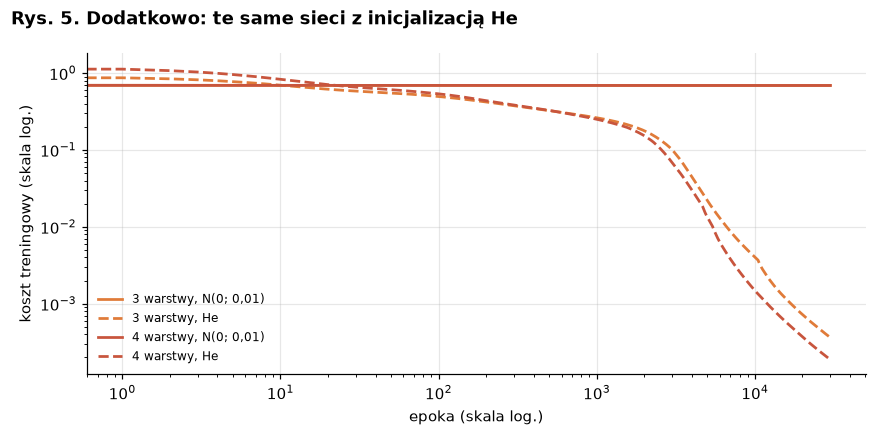

,wyjście z plateau,min. koszt val,epoka min. val,F1 test (early stopping)
"3 warstwy, N(0; 0,01)",—,0.69,29972,0.0
"3 warstwy, He",24.0,0.419,582.0,0.772
"4 warstwy, N(0; 0,01)",—,0.69,1799,0.0
"4 warstwy, He",55.0,0.463,709.0,0.772


In [12]:
rows = {}
fig, ax = plt.subplots(figsize=(8, 4))
for col, n in [("#e07b39", 3), ("#c8553d", 4)]:
    for init, ls in [("normal", "-"), ("he", "--")]:
        m = MLP(d, (d,) * n, init=init, seed=0).fit(Xtr, ytr, Xva, yva, epochs=E, log_every=100)
        name = f"{n} warstwy, " + ("N(0; 0,01)" if init == "normal" else "He")
        ex = epochs_to(m.history["loss"], PLATEAU)
        rows[name] = {"wyjście z plateau": ex if ex is not None else "—", "min. koszt val": round(m.best_val_loss, 3),
                      "epoka min. val": m.best_epoch,
                      "F1 test (early stopping)": round(metrics(yte, m.early_stopping_proba(Xte))["f1"], 3)}
        ax.plot(m.history["loss"], ls, c=col, lw=1.8, label=name)
ax.set(xscale="log", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)")
ax.legend(fontsize=8)
rys(fig, 5, "Dodatkowo: te same sieci z inicjalizacją He")
pd.DataFrame(rows).T

**Jak czytać Rys. 5:** linie ciągłe to wagi N(0; 0,01) jak w treści, przerywane to inicjalizacja He. Pomarańczowe: 3 warstwy ukryte, czerwone: 4. Obie osie logarytmiczne.

**Obserwacje:** z inicjalizacją He sieci z 3 i 4 warstwami wychodzą z plateau po **24 i 55 epokach** zamiast po ok. 94 600 epokach albo wcale. Najniższy koszt walidacyjny (0,42 i 0,46) jest w epokach 582 i 709, a F1 testowe przy early stopping wynosi 0,772.

> **Wniosek:** problemem głębszych sieci w tym ćwiczeniu nie jest ich głębokość, tylko inicjalizacja zbyt małymi wagami. Ten temat rozwija druga część ćwiczenia.

## 8. Podsumowanie

| czynnik | wpływ na uczenie | wpływ na jakość (F1 test, early stopping) | dowód |
|---|---|---|---|
| szerokość 2–4 (mniej niż 17 cech) | dłuższe plateau, mniejsza pojemność | ok. 0,76 | Rys. 2 |
| szerokość 17 (równo) | plateau ok. 770 epok | 0,764 | Rys. 1–2 |
| szerokość 68–256 (dużo więcej) | krótsze plateau, szybsze przeuczenie | ok. 0,76 | Rys. 2 |
| brak normalizacji | regresja logistyczna się rozbiega, MLP utyka na koszcie 0,52 | 0,63–0,67 | Rys. 3 |
| min-max / standaryzacja | uczenie działa, standaryzacja szybciej | 0,75–0,77 | Rys. 3 |
| więcej warstw (N(0; 0,01)) | plateau ok. 10 razy dłuższe na warstwę, 4 warstwy nie ruszają | bez poprawy, 0 dla 4 warstw | Rys. 4 |
| inicjalizacja He | brak plateau także dla 3–4 warstw | 0,772 | Rys. 5 |

## 9. Wnioski

Propagacja wsteczna zaimplementowana jako sekwencja modułów z `forward` i `backward` daje gradienty zgodne z numerycznymi do ok. 10⁻¹⁰, a sieć bez warstw ukrytych odtwarza regresję logistyczną z ćw. 2. Przy wagach N(0; 0,01) i α = 0,01 każda sieć z warstwą ukrytą zaczyna od plateau na koszcie 0,69, bo małe wagi dają p ≈ 0,5 i prawie zerowy gradient. Szerokość warstwy ukrytej zmienia głównie szybkość uczenia: szersza sieć szybciej opuszcza plateau i szybciej się przeucza, ale przy early stopping F1 testowe wynosi ok. 0,76 dla 2, 17 i 256 neuronów. Bez normalizacji danych sieć się nie uczy (koszt 0,52, F1 0,67), a regresja logistyczna wręcz się rozbiega, więc normalizacja, najlepiej standaryzacja, jest konieczna. Każda kolejna warstwa wydłuża plateau ok. dziesięciokrotnie, a sieć z czterema warstwami nie rusza w 150 000 epok, bo gradient maleje kilka do kilkudziesięciu razy na każdą warstwę w stronę wejścia. Inicjalizacja He usuwa ten problem, więc przyczyną jest zanikający gradient przy zbyt małych wagach, a nie sama głębokość. Na tak małym zbiorze żadna sieć wielowarstwowa nie była lepsza od regresji logistycznej, a wszystkie bez warunku stopu silnie się przeuczały.